# Week 3 — Robot Performance KPI & Anomaly Detection Pipeline

**InGen Dynamics | Data Analyst Internship | September 28 – October 3, 2026**  
**Platforms:** Aido Rover, Sentinel Prime AI, Fari  
**Input:** `W02_Robot_Deployment_Dataset.csv` (**SYNTHETIC**, January–December 2025)

### Questions answered
1. How do operational KPIs change month to month, and against their demo alert thresholds?
2. Which deployment-month observations are flagged by the configurable anomaly pipeline?
3. How accurately do the rules recover the labeled synthetic anomalies?
4. Which deployments contribute most to a selected platform-month KPI deviation?

**Important limitation:** This is a retrospective demonstration on synthetic data. Results do not estimate performance on InGen's real deployments. The first-three-month reference is part of the illustrative detector, not a point-in-time forecasting protocol. An anomaly contribution is a descriptive decomposition, **not** a causal root-cause diagnosis.

## 1 · Environment and data loading

Run cells from top to bottom. The notebook should be placed directly in the same **`week3_step2`** folder as `src/`, `config/`, `data/`, and `outputs/`. When prompted, select your project's `.venv` Python kernel.

The project code lives in `src/anomaly_detection.py`; this notebook **calls the module** rather than rebuilding a different implementation.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Locate the project even if VS Code starts the notebook from another directory.
working_dir = Path.cwd().resolve()
candidates = [working_dir, *working_dir.parents]
project_dir = next((p for p in candidates if (p / "src" / "anomaly_detection.py").exists()), None)
if project_dir is None:
    raise FileNotFoundError("Open week3_step2 in VS Code and put this notebook in its root folder.")

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.anomaly_detection import (
    load_data, load_kpi_config, calculate_kpis, detect_anomalies,
    contribution_analysis, build_anomaly_report, evaluate_against_labels,
)

data_path = project_dir / "data" / "W02_Robot_Deployment_Dataset.csv"
config_path = project_dir / "config" / "W03_KPI_Framework.xlsx"

data = load_data(data_path)
config = load_kpi_config(config_path)
print("Project folder found successfully: src / config / data are available")
print("Dataset:", len(data), "deployment-month rows")
print("Platforms:", data["platform"].nunique())
print("KPI configurations:", len(config))
print("Data label:", ", ".join(data["data_label"].unique()))

Project folder found successfully: src / config / data are available
Dataset: 360 deployment-month rows
Platforms: 3
KPI configurations: 15
Data label: SYNTHETIC


In [2]:
overview = (
    data.groupby("platform", as_index=False)
        .agg(deployment_months=("deployment_id", "size"),
             deployments=("deployment_id", "nunique"),
             planted_anomalies=("anomaly_flag", "sum"))
)
display(overview)
display(config[["platform", "kpi_id", "kpi_name", "better_when", "alert_operator", "alert_threshold"]])

,platform,deployment_months,deployments,planted_anomalies
0,Aido Rover,120,10,10
1,Fari,120,10,14
2,Sentinel Prime AI,120,10,14


,platform,kpi_id,kpi_name,better_when,alert_operator,alert_threshold
0,Aido Rover,AR01,Patrol Coverage Rate,Higher,<,90.0
1,Aido Rover,AR02,Incident Detection Rate,Higher,<,83.0
2,Aido Rover,AR03,Battery Consumption per Cycle,Lower,>,19.0
3,Aido Rover,AR04,Uptime Percentage,Higher,<,95.0
4,Aido Rover,AR05,Shift Completion Rate,Higher,<,90.0
5,Sentinel Prime AI,SP01,Patrol Coverage Rate,Higher,<,90.0
6,Sentinel Prime AI,SP02,Incident Detection Rate,Higher,<,88.0
7,Sentinel Prime AI,SP03,Battery Consumption per Cycle,Lower,>,17.0
8,Sentinel Prime AI,SP04,Uptime Percentage,Higher,<,96.0
9,Sentinel Prime AI,SP05,Shift Completion Rate,Higher,<,92.0


## 2 · KPI calculation, MoM change and rolling-4 averages

Each row in the synthetic CSV represents a **deployment-month**, not an underlying event log. Thus platform-month summaries are equal-weight means of the supplied KPI readings; event-level numerators and denominators are unavailable. **FA05** is the derived estimate *average session duration × daily engagement sessions*.

In [3]:
readings, monthly = calculate_kpis(data, config)
print("Deployment-KPI readings:", len(readings))
print("Platform-month KPI summaries:", len(monthly))

# Show representative Aido Rover coverage values and their month-over-month changes.
coverage = monthly.loc[(monthly["platform"] == "Aido Rover") & (monthly["kpi_id"] == "AR01")].copy()
display(coverage[["date", "mean_value", "mom_change", "rolling4_mean", "rolling4_change"]].round(2))

Deployment-KPI readings: 1800
Platform-month KPI summaries: 180


,date,mean_value,mom_change,rolling4_mean,rolling4_change
0,2025-01-01,90.13,NaN,90.13,NaN
1,2025-02-01,92.40,2.27,91.26,1.14
2,2025-03-01,95.21,2.81,92.58,1.31
3,2025-04-01,95.32,0.11,93.26,0.69
4,2025-05-01,92.36,-2.96,93.82,0.56
5,2025-06-01,89.13,-3.23,93.00,-0.82
6,2025-07-01,91.32,2.19,92.03,-0.97
7,2025-08-01,92.56,1.24,91.34,-0.69
8,2025-09-01,94.50,1.94,91.88,0.53
9,2025-10-01,95.34,0.84,93.43,1.55


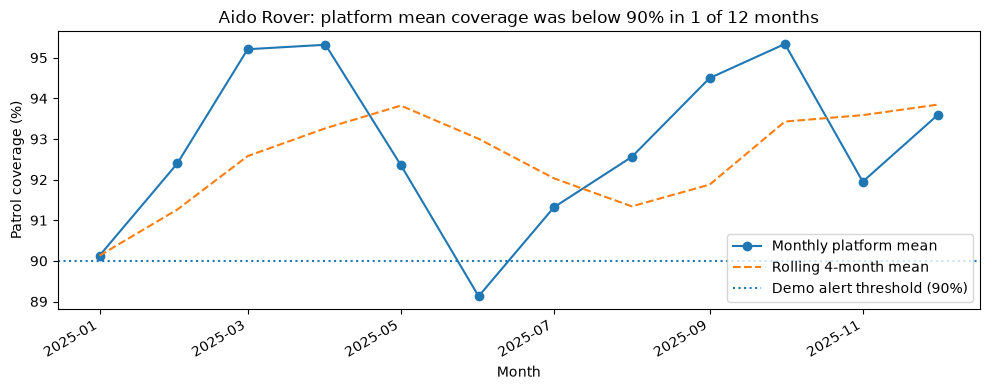

In [4]:
coverage_threshold = float(config.loc[config["kpi_id"] == "AR01", "alert_threshold"].iloc[0])
below_months = int((coverage["mean_value"] < coverage_threshold).sum())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(coverage["date"], coverage["mean_value"], marker="o", label="Monthly platform mean")
ax.plot(coverage["date"], coverage["rolling4_mean"], linestyle="--", label="Rolling 4-month mean")
ax.axhline(coverage_threshold, linestyle=":", label=f"Demo alert threshold ({coverage_threshold:g}%)")
ax.set_title(f"Aido Rover: platform mean coverage was below {coverage_threshold:g}% in {below_months} of 12 months")
ax.set_ylabel("Patrol coverage (%)")
ax.set_xlabel("Month")
ax.legend(loc="best")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 3 · Parameterized anomaly detection

The Python module calculates operational threshold flags, prior-history Z-scores, distribution-tail flags and Tukey-IQR diagnostics. Final **deployment-month** flags combine these signals with the specified Fari engagement trend rule. The `anomaly_flag` label is **not used for prediction**; it is evaluated separately afterward.

**Method note:** A bottom/top 10% tail check and Tukey IQR fences are two different diagnostics, not interchangeable definitions of “IQR.” Only deviations in the unhealthy direction contribute to statistical confirmations.

In [5]:
scored, predictions = detect_anomalies(readings)
report = build_anomaly_report(scored)
metrics = evaluate_against_labels(predictions, data)

print("Deployment-month predictions:", len(predictions))
print("Predicted anomalous deployment-months:", metrics["predicted_anomalies"])
print("Flagged KPI detail rows:", len(report))
print("A single flagged deployment-month can appear in several KPI detail rows.")

summary = pd.DataFrame({
    "metric": ["Synthetic labeled anomalies", "Predicted deployment-month anomalies",
               "True positives", "False positives", "False negatives", "True negatives",
               "Recall", "Precision", "False-positive rate"],
    "value": [metrics["planted_anomalies"], metrics["predicted_anomalies"],
              metrics["true_positive"], metrics["false_positive"],
              metrics["false_negative"], metrics["true_negative"],
              f'{metrics["recall"]:.2%}', f'{metrics["precision"]:.2%}',
              f'{metrics["false_positive_rate"]:.2%}'],
})
display(summary)

Deployment-month predictions: 360
Predicted anomalous deployment-months: 40
Flagged KPI detail rows: 151
A single flagged deployment-month can appear in several KPI detail rows.


,metric,value
0,Synthetic labeled anomalies,38
1,Predicted deployment-month anomalies,40
2,True positives,38
3,False positives,2
4,False negatives,0
5,True negatives,320
6,Recall,100.00%
7,Precision,95.00%
8,False-positive rate,0.62%


,platform,planted_anomalies,predicted_anomalies
0,Aido Rover,10,10
1,Fari,14,16
2,Sentinel Prime AI,14,14


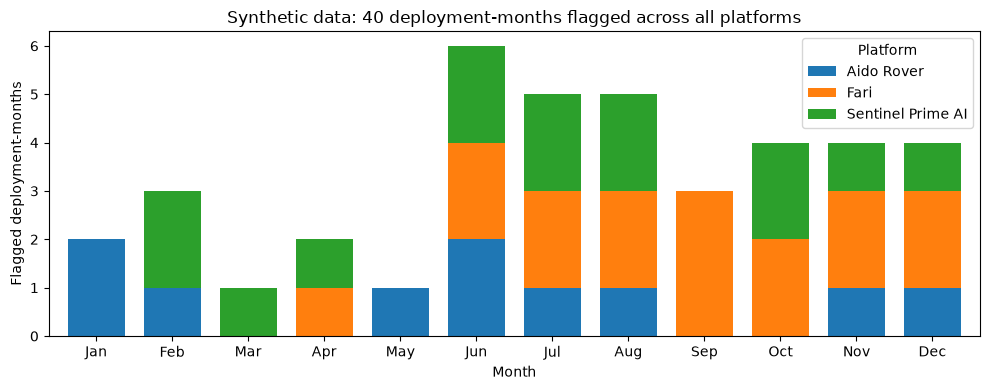

In [6]:
labeled = predictions.merge(
    data[["deployment_id", "date", "anomaly_flag"]],
    on=["deployment_id", "date"],
    validate="one_to_one",
)
platform_eval = (
    labeled.groupby("platform", as_index=False)
    .agg(planted_anomalies=("anomaly_flag", "sum"),
         predicted_anomalies=("pred_anomaly", "sum"))
)
display(platform_eval)

monthly_alerts = (
    labeled.loc[labeled["pred_anomaly"] == 1]
    .groupby(["date", "platform"]).size().unstack(fill_value=0)
)
# Anomaly counts (not KPI row counts) across the three robot platforms.
fig, ax = plt.subplots(figsize=(10, 4))
monthly_alerts.plot(kind="bar", stacked=True, ax=ax, width=0.75)
ax.set_title(f"Synthetic data: {metrics['predicted_anomalies']} deployment-months flagged across all platforms")
ax.set_ylabel("Flagged deployment-months")
ax.set_xlabel("Month")
ax.set_xticklabels([pd.Timestamp(x).strftime("%b") for x in monthly_alerts.index], rotation=0)
ax.legend(title="Platform", loc="best")
plt.tight_layout()
plt.show()

### Inspect false positives and missed labeled anomalies

The two categories must be evaluated separately. A false positive is a record with `anomaly_flag == 0` and `pred_anomaly == 1`. A false negative is a planted abnormal record not caught by the pipeline.

In [7]:
false_positives = labeled.loc[(labeled["anomaly_flag"] == 0) & (labeled["pred_anomaly"] == 1),
                              ["platform", "deployment_id", "date", "pred_anomaly", "anomaly_flag"]]
false_negatives = labeled.loc[(labeled["anomaly_flag"] == 1) & (labeled["pred_anomaly"] == 0),
                              ["platform", "deployment_id", "date", "pred_anomaly", "anomaly_flag"]]
print(f"False positives: {len(false_positives)}")
display(false_positives)
print(f"False negatives: {len(false_negatives)}")
display(false_negatives)

False positives: 2


,platform,deployment_id,date,pred_anomaly,anomaly_flag
128,Fari,FARI-001,2025-09-01,1,0
147,Fari,FARI-003,2025-04-01,1,0


False negatives: 0


,platform,deployment_id,date,pred_anomaly,anomaly_flag


## 4 · Contribution analysis (descriptive attribution)

For a selected **Aido Rover patrol-coverage** anomaly month, the module compares the ten deployments' readings with their first-three-month deployment-specific reference means. Their **signed contributions add up to the total platform mean deviation**. `allocated_deviation` distributes the absolute *net* deviation among same-direction contributors.

This is a statistical accounting of the observed change; it does **not** establish why a particular robot's performance changed.

In [8]:
ar_alerts = report.loc[(report["platform"] == "Aido Rover") & (report["kpi_id"] == "AR01")]
if ar_alerts.empty:
    raise ValueError("No AR01 anomaly records available for a contribution example")

# Choose the AR01 anomaly month with the largest individual KPI deviation.
selected = ar_alerts.sort_values("deviation_magnitude", ascending=False).iloc[0]
chosen_month = pd.Timestamp(selected["date"])
contrib = contribution_analysis(scored, "Aido Rover", chosen_month, "AR01")

signed_total = float(contrib["signed_contribution"].sum())
allocated_total = float(contrib["allocated_deviation"].sum())
print("Selected month:", chosen_month.strftime("%Y-%m"))
print("Signed platform-mean deviation:", round(signed_total, 4))
print("Absolute allocated deviation:", round(allocated_total, 4))
print("Largest statistical contributor:", contrib.iloc[0]["deployment_id"])
assert np.isclose(signed_total, contrib["total_signed_deviation"].iloc[0])
assert np.isclose(allocated_total, abs(signed_total))

display(contrib[["deployment_id", "value", "ref", "signed_contribution", "allocated_deviation", "share_pct"]].round(3))

Selected month: 2025-06
Signed platform-mean deviation: -3.45
Absolute allocated deviation: 3.45
Largest statistical contributor: AIDO-005


,deployment_id,value,ref,signed_contribution,allocated_deviation,share_pct
0,AIDO-005,57.0,88.267,-3.127,2.415,70.000
1,AIDO-010,71.7,82.567,-1.087,0.839,24.328
2,AIDO-007,95.8,97.067,-0.127,0.098,2.836
3,AIDO-009,92.4,93.133,-0.073,0.057,1.642
4,AIDO-001,95.9,96.433,-0.053,0.041,1.194
5,AIDO-002,95.2,94.200,0.100,0.000,0.000
6,AIDO-003,95.8,95.733,0.007,0.000,0.000
7,AIDO-004,98.4,95.600,0.280,0.000,0.000
8,AIDO-006,95.6,95.167,0.043,0.000,0.000
9,AIDO-008,93.5,87.633,0.587,0.000,0.000


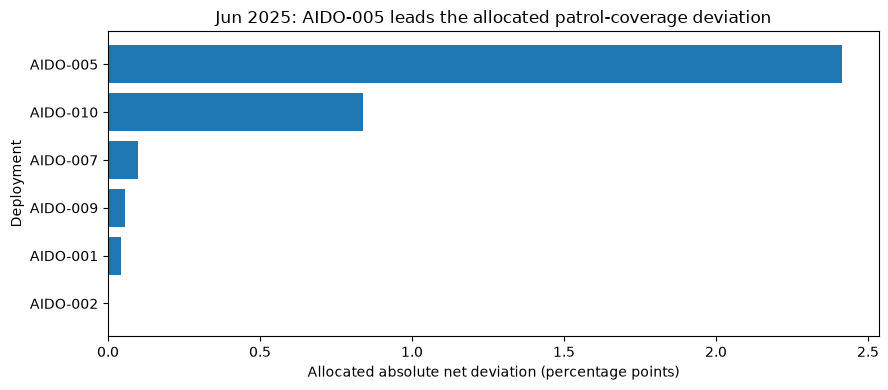

In [9]:
top_contributors = contrib.head(6).sort_values("allocated_deviation")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top_contributors["deployment_id"], top_contributors["allocated_deviation"])
ax.set_title(f"{chosen_month:%b %Y}: {contrib.iloc[0]['deployment_id']} leads the allocated patrol-coverage deviation")
ax.set_xlabel("Allocated absolute net deviation (percentage points)")
ax.set_ylabel("Deployment")
plt.tight_layout()
plt.show()

## 5 · Threshold sensitivity

The configured Z-score cutoff is 2.0. Lowering it to 1.5 should flag at least as many **KPI-level Z-scores**. The final deployment-month decision also depends on other rules, so a change in individual Z flags does **not guarantee** a change in the final alert count.

In [10]:
scored_lower, predictions_lower = detect_anomalies(readings, z_cutoff_override=1.5)
sensitivity = pd.DataFrame({
    "Cutoff": [2.0, 1.5],
    "KPI-level Z-score flags": [int(scored["z_flag"].sum()), int(scored_lower["z_flag"].sum())],
    "Final deployment-month alerts": [int(predictions["pred_anomaly"].sum()),
                                      int(predictions_lower["pred_anomaly"].sum())],
})
display(sensitivity)
assert sensitivity.loc[1, "KPI-level Z-score flags"] >= sensitivity.loc[0, "KPI-level Z-score flags"]
print("Configured statistical cutoff sensitivity evaluated successfully.")

,Cutoff,KPI-level Z-score flags,Final deployment-month alerts
0,2.0,98,40
1,1.5,181,41


Configured statistical cutoff sensitivity evaluated successfully.


## 6 · Final structured anomaly report and reconciliation

The anomaly report is **KPI-level**: one deployment-month may have several rows. The table shows the affected KPI, measured value, magnitude of deviation, descriptive top contributing deployment, and severity category. **HIGH/MEDIUM are demo labels defined in the source module**, not independently validated operational incident grades.

In [11]:
most_recent = report.sort_values(["date", "severity"], ascending=[False, True]).head(10)
display(most_recent[["platform", "date", "deployment_id", "kpi_name",
                     "value", "deviation_magnitude", "primary_contributing_subsegment", "severity"]])

# Reconciliation: all report rows correspond to model-flagged deployment-months.
flagged_keys = predictions.loc[predictions["pred_anomaly"].eq(1),
                                ["platform", "deployment_id", "date"]].drop_duplicates()
all_report_keys = report[["platform", "deployment_id", "date"]].drop_duplicates()
joined = all_report_keys.merge(flagged_keys, on=["platform", "deployment_id", "date"], how="left", indicator=True)
assert joined["_merge"].eq("both").all()
assert len(monthly) == 15 * 12
assert len(readings) == len(data) * 5
assert len(predictions) == len(data)
print("Reconciliation passed: report rows map to flagged deployments and KPI totals match the input.")
print("KPI report rows:", len(report))
print("Distinct flagged deployment-months represented in report:", len(all_report_keys))
print("Final deployment-month alerts:", metrics["predicted_anomalies"])

,platform,date,deployment_id,kpi_name,value,deviation_magnitude,primary_contributing_subsegment,severity
136,Aido Rover,2025-12-01,AIDO-001,Patrol Coverage Rate,75.50,19.45,AIDO-010,HIGH
137,Aido Rover,2025-12-01,AIDO-001,Uptime Percentage,93.60,4.25,AIDO-005,HIGH
139,Fari,2025-12-01,FARI-003,Average Session Duration,12.50,13.85,FARI-003,HIGH
143,Fari,2025-12-01,FARI-008,Average Session Duration,12.90,13.45,FARI-003,HIGH
148,Sentinel Prime AI,2025-12-01,SENT-003,Patrol Coverage Rate,63.20,32.75,SENT-003,HIGH
150,Sentinel Prime AI,2025-12-01,SENT-003,Shift Completion Rate,79.10,17.95,SENT-004,HIGH
138,Aido Rover,2025-12-01,AIDO-001,Shift Completion Rate,87.60,8.45,AIDO-001,MEDIUM
140,Fari,2025-12-01,FARI-003,Daily Engagement Sessions,2.50,3.20,FARI-008,MEDIUM
141,Fari,2025-12-01,FARI-003,Caregiver App Interactions,2.70,1.60,FARI-003,MEDIUM
142,Fari,2025-12-01,FARI-003,Daily Engagement Minutes (Derived),31.25,118.66,FARI-003,MEDIUM


Reconciliation passed: report rows map to flagged deployments and KPI totals match the input.
KPI report rows: 151
Distinct flagged deployment-months represented in report: 40
Final deployment-month alerts: 40


## 7 · Findings, assumptions and limitations

**Interpretation (from the executed outputs):**
- The detector identifies synthetic operational anomalies at **deployment-month** granularity. A single flagged event can surface as multiple KPI-level report entries.
- Recall, precision and false-positive rate above are calculated **only against labels planted in this 360-record simulated dataset**. They should not be presented as proven field performance.
- The KPI alert thresholds in the workbook are **editable demonstration settings**, not company-approved production thresholds or direct equivalents of public benchmarks.
- The first-three-month pooled reference used for some early detections is retrospective. No prospective deployment claim or no-look-ahead forecast claim is made.
- The contribution chart ranks **which deployments statistically account for a deviation**, not verified operational root causes.

**Next Week 3 deliverable:** `tests/test_anomaly.py` with 30+ tests, including label-based detection, false-positive rate, manual KPI checks, configurable thresholds and attribution reconciliation.

**Week 4 handoff:** Reuse `src/anomaly_detection.py` in the three-tab Streamlit dashboard; do not redefine KPI formulas separately inside the dashboard.